<a href="https://colab.research.google.com/github/binary-cpu/chokepoint-tracker/blob/main/04_post1_chart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data snapshot: through 2026-10-11, accessed 2026-10-14.

Source: UN Global Platform; IMF PortWatch

# **CELL A: data pull**

rows: 79548 | chokepoints: 28 | span: 2019-01-01 to 2026-10-11
duplicate (portid, date) rows: 0
chokepoints with missing days: 0
columns: ['date', 'year', 'month', 'day', 'portid', 'portname', 'n_container', 'n_dry_bulk', 'n_general_cargo', 'n_roro', 'n_tanker', 'n_cargo', 'n_total', 'capacity_container', 'capacity_dry_bulk', 'capacity_general_cargo', 'capacity_roro', 'capacity_tanker', 'capacity_cargo', 'capacity', 'ObjectId']
matched names: ['Bab el-Mandeb Strait', 'Cape of Good Hope', 'Strait of Hormuz', 'Suez Canal']


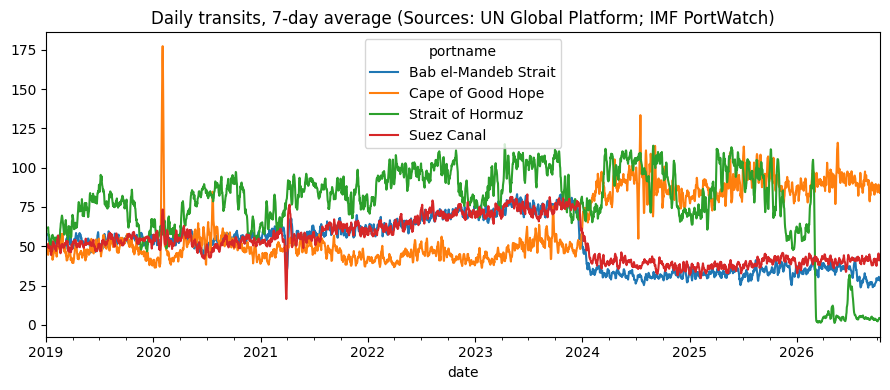

In [2]:
%pip -q install requests pandas matplotlib
import requests, pandas as pd
import matplotlib.pyplot as plt

BASE = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer"
CHOKE_DB = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/PortWatch_chokepoints_database/FeatureServer"

def layer_url(base):
    info = requests.get(base, params={"f": "json"}, timeout=60).json()
    # Safely get layer ID; if 'layers' is empty or missing, assume the first layer is 0 or base already contains it
    layers = info.get('layers', [])
    if layers:
        layer_id = layers[0]['id']
        return f"{base}/{layer_id}/query"
    elif base.endswith(tuple(str(i) for i in range(10))):
        return f"{base}/query"
    else:
        return f"{base}/0/query"

def fetch_all(base, order=None, page=1000):
    url, rows, offset = layer_url(base), [], 0
    while True:
        params = {"where": "1=1", "outFields": "*", "returnGeometry": "false",
                  "resultOffset": offset, "resultRecordCount": page, "f": "json"}
        if order:
            params["orderByFields"] = order
        r = requests.get(url, params=params, timeout=120).json()
        if "error" in r:
            raise RuntimeError(r["error"])
        feats = r.get("features", [])
        rows += [f["attributes"] for f in feats]
        if not feats or not r.get("exceededTransferLimit"):
            break
        offset += len(feats)
    return pd.DataFrame(rows)

daily = fetch_all(BASE, order="date,portid")
chokes = fetch_all(CHOKE_DB, order="portid")
if pd.api.types.is_numeric_dtype(daily["date"]):
    daily["date"] = pd.to_datetime(daily["date"], unit="ms")
else:
    daily["date"] = pd.to_datetime(daily["date"])

print("rows:", len(daily), "| chokepoints:", daily.portid.nunique(),
      "| span:", daily.date.min().date(), "to", daily.date.max().date())
print("duplicate (portid, date) rows:", int(daily.duplicated(["portid", "date"]).sum()))
span_days = (daily.date.max() - daily.date.min()).days + 1
print("chokepoints with missing days:", int((daily.groupby("portid").date.nunique() < span_days).sum()))
print("columns:", list(daily.columns))

pick = daily[daily.portname.str.contains("Suez|Bab|Hormuz|Cape of Good Hope", case=False, na=False)]
print("matched names:", sorted(pick.portname.unique()))
piv = pick.pivot(index="date", columns="portname", values="n_total").rolling(7).mean()
piv.plot(figsize=(9, 4), title="Daily transits, 7-day average (Sources: UN Global Platform; IMF PortWatch)")
plt.tight_layout(); plt.show()


# **CELL B: refresh the sensitivity ranges**

In [5]:
FOCUS = ["Suez Canal", "Bab el-Mandeb Strait", "Strait of Hormuz", "Cape of Good Hope"]
f = daily[daily.portname.isin(FOCUS)].copy()
latest = daily.date.max(); recent_start = latest - pd.Timedelta(days=27)

In [6]:
h = daily[daily.portname == "Strait of Hormuz"].set_index("date").n_total
print("Hormuz transits 21-27 Sep 2026 in this snapshot:", int(h["2026-09-21":"2026-09-27"].sum()), "(notebook 02 snapshot gave 22)")


Hormuz transits 21-27 Sep 2026 in this snapshot: 22 (notebook 02 snapshot gave 22)


# **CELL C: the chart for post 1**

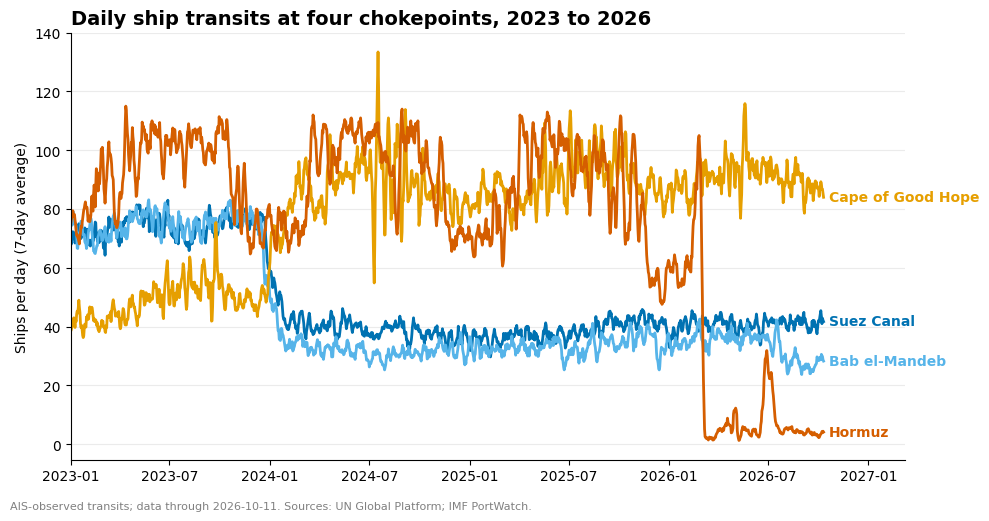

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import matplotlib.pyplot as plt
NAMES = {"Suez Canal": "Suez Canal", "Bab el-Mandeb Strait": "Bab el-Mandeb", "Cape of Good Hope": "Cape of Good Hope", "Strait of Hormuz": "Hormuz"}
COLORS = {"Suez Canal": "#0072B2", "Bab el-Mandeb Strait": "#56B4E9", "Cape of Good Hope": "#E69F00", "Strait of Hormuz": "#D55E00"}
d = daily[daily.portname.isin(NAMES)].pivot(index="date", columns="portname", values="n_total").rolling(7).mean().loc["2023-01-01":]
fig, ax = plt.subplots(figsize=(10, 5.2))
for name, short in NAMES.items():
    ax.plot(d.index, d[name], color=COLORS[name], linewidth=2)
    ax.text(d.index[-1] + pd.Timedelta(days=10), d[name].iloc[-1], short, color=COLORS[name], va="center", fontsize=10, fontweight="bold")
ax.set_xlim(d.index[0], d.index[-1] + pd.Timedelta(days=150))
ax.set_ylabel("Ships per day (7-day average)")
ax.set_title("Daily ship transits at four chokepoints, 2023 to 2026", loc="left", fontsize=14, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
fig.text(0.01, 0.01, f"AIS-observed transits; data through {daily.date.max().date()}. Sources: UN Global Platform; IMF PortWatch.", fontsize=8, color="gray")
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.savefig("post1_chokepoints.png", dpi=200)
plt.show()
from google.colab import files; files.download("post1_chokepoints.png")